In [5]:
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

RESULTS_CSV = Path("../outputs/results/final_test_metrics_pcb.csv")
LOG_DIR = Path("../outputs/logs")
FIG_DIR = Path("../outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# 1. Print Final D2t Test Set Performance Table
df_test = pd.read_csv(RESULTS_CSV)
display(df_test.sort_values(by="Test Rank-1", ascending=False))

# 2. Load Joblib Histories
backbones = {
    "convnext_tiny": "ConvNeXt-Tiny",
    "efficientnet_v2_s": "EfficientNetV2-S",
    "mobilenetv4": "MobileNetV4",
}

histories = {}
for key, label in backbones.items():
    hist_file = LOG_DIR / f"pcb_{key}_history.joblib"
    if hist_file.exists():
        histories[key] = (label, joblib.load(hist_file))
    else:
        print(f"Warning: {hist_file} not found.")

,Architecture,Backbone,Best Epoch,Test mAP,Test Rank-1,Test Rank-5,Test Rank-10
0,PCB,convnext_tiny,15,0.8033,0.8354,0.9671,0.9835
1,PCB,efficientnet_v2_s,33,0.6635,0.6955,0.9136,0.9465
2,PCB,mobilenetv4,49,0.6649,0.6461,0.8971,0.9753


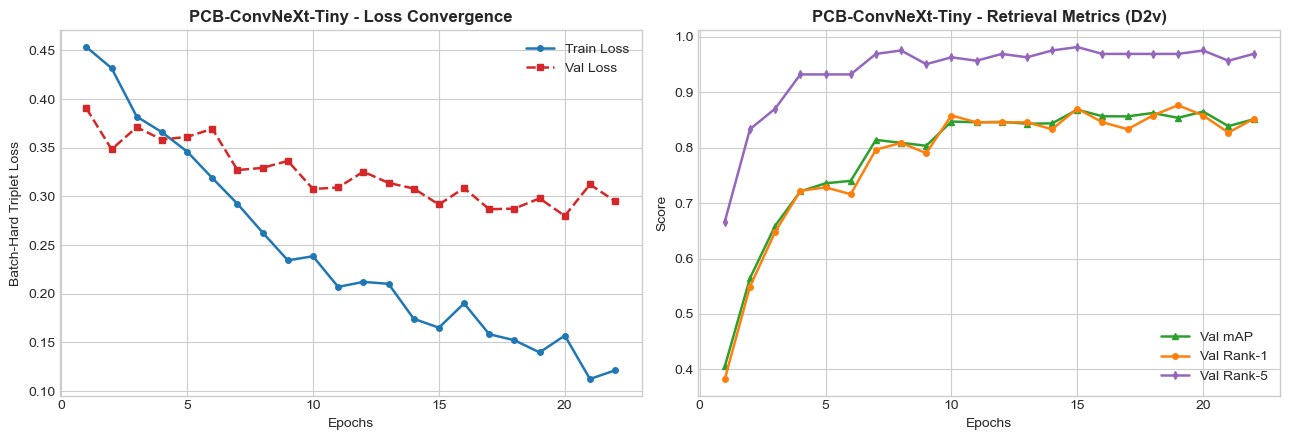

Saved ..\outputs\figures\pcb_convnext_tiny_curves.png


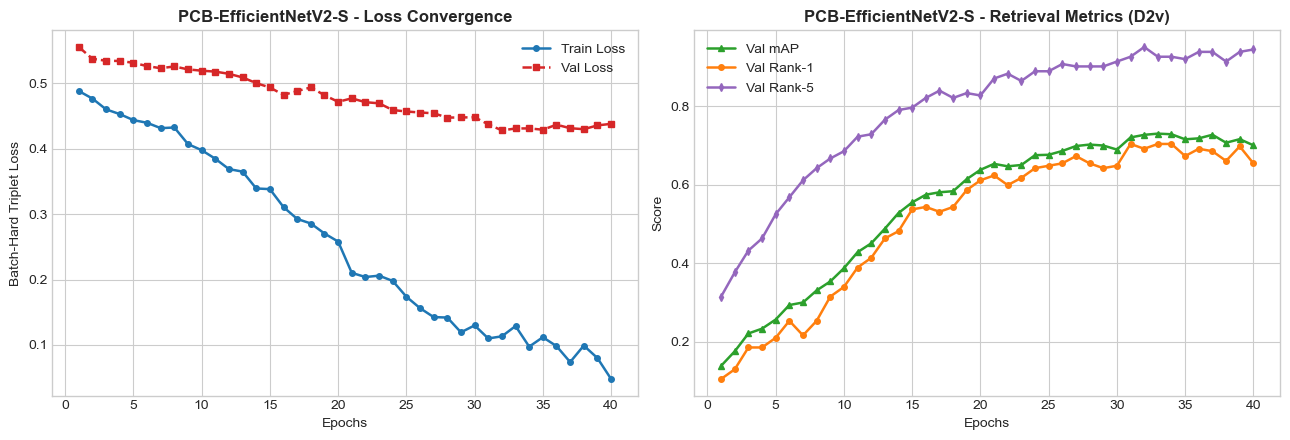

Saved ..\outputs\figures\pcb_efficientnet_v2_s_curves.png


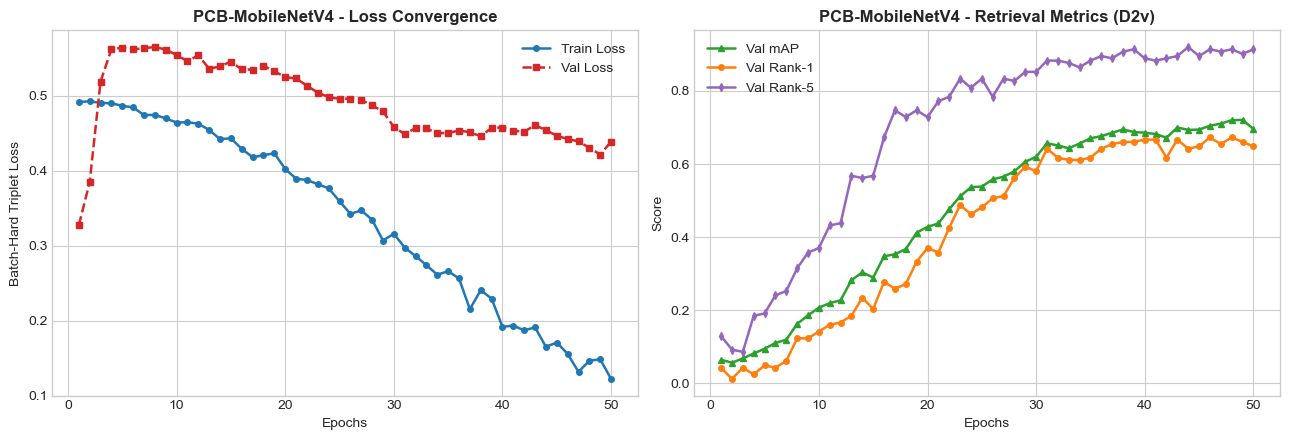

Saved ..\outputs\figures\pcb_mobilenetv4_curves.png


In [6]:
for key, (label, hist) in histories.items():
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    epochs = hist["epoch"]

    # Left Panel: Batch-Hard Triplet Loss Convergence
    axes[0].plot(epochs, hist["train_loss"], marker="o", markersize=4, linewidth=1.8, color="#1f77b4", label="Train Loss")
    if "val_loss" in hist:
        axes[0].plot(epochs, hist["val_loss"], marker="s", markersize=4, linestyle="--", linewidth=1.8, color="#d62728", label="Val Loss")
    axes[0].set_title(f"PCB-{label} - Loss Convergence", fontweight="bold")
    axes[0].set_xlabel("Epochs")
    axes[0].set_ylabel("Batch-Hard Triplet Loss")
    axes[0].legend()

    # Right Panel: Validation Retrieval Metrics (D2v)
    axes[1].plot(epochs, hist["val_mAP"], marker="^", markersize=4, linewidth=1.8, color="#2ca02c", label="Val mAP")
    axes[1].plot(epochs, hist["val_rank1"], marker="o", markersize=4, linewidth=1.8, color="#ff7f0e", label="Val Rank-1")
    axes[1].plot(epochs, hist["val_rank5"], marker="d", markersize=4, linewidth=1.8, color="#9467bd", label="Val Rank-5")
    axes[1].set_title(f"PCB-{label} - Retrieval Metrics (D2v)", fontweight="bold")
    axes[1].set_xlabel("Epochs")
    axes[1].set_ylabel("Score")
    axes[1].legend()

    plt.tight_layout()
    out_fig = FIG_DIR / f"pcb_{key}_curves.png"
    plt.savefig(out_fig, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved {out_fig}")

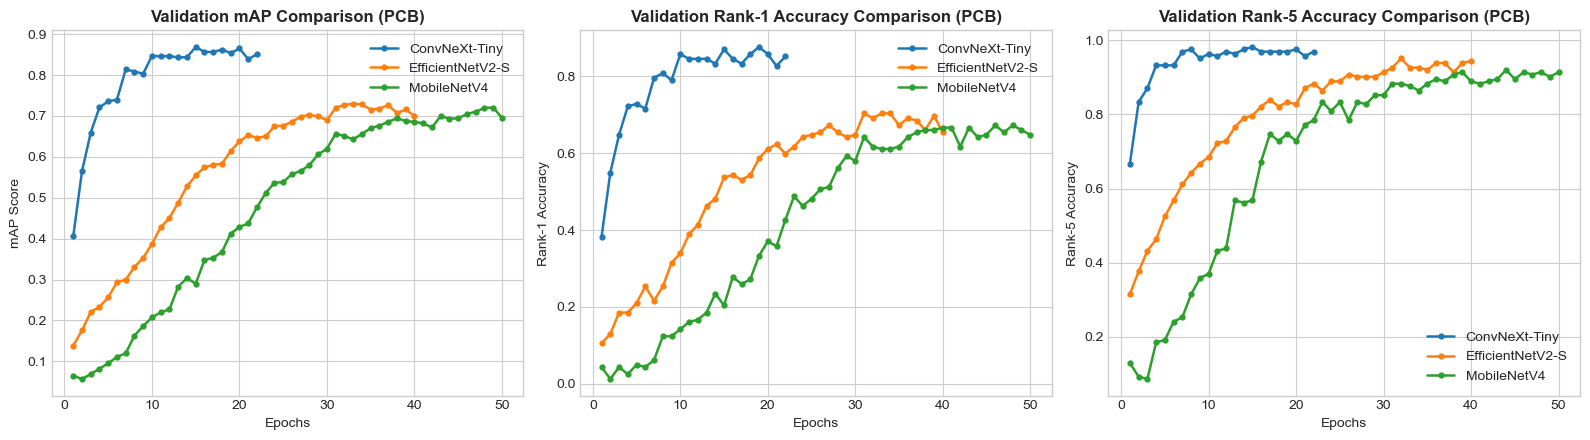

Saved ..\outputs\figures\pcb_backbone_comparison.png


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
metrics_to_plot = [
    ("val_mAP", "Validation mAP Comparison (PCB)", "mAP Score"),
    ("val_rank1", "Validation Rank-1 Accuracy Comparison (PCB)", "Rank-1 Accuracy"),
    ("val_rank5", "Validation Rank-5 Accuracy Comparison (PCB)", "Rank-5 Accuracy"),
]

for ax, (metric_key, title, ylabel) in zip(axes, metrics_to_plot):
    for key, (label, hist) in histories.items():
        ax.plot(hist["epoch"], hist[metric_key], marker="o", markersize=3.5, linewidth=1.8, label=label)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Epochs")
    ax.set_ylabel(ylabel)
    ax.legend()

plt.tight_layout()
comp_fig = FIG_DIR / "pcb_backbone_comparison.png"
plt.savefig(comp_fig, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved {comp_fig}")